In [2]:
import pandas as pd
import numpy as np
import seaborn as sns

### First we load dataset.

In [3]:
dataset = pd.read_excel("data_accepted_2015.xlsx")

### Delete last 3 columns, they mean nothing.

In [4]:
dataset = dataset.iloc[:,:-3]

### Get data info, we see 226.6 MB (too much).

In [5]:
dataset.info(memory_usage="deep")

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 421095 entries, 0 to 421094
Data columns (total 16 columns):
 #   Column          Non-Null Count   Dtype  
---  ------          --------------   -----  
 0   id              421095 non-null  int64  
 1   year            421095 non-null  int64  
 2   funded_amnt     421095 non-null  int64  
 3   term            421095 non-null  object 
 4   grade           421095 non-null  object 
 5   emp_title       397221 non-null  object 
 6   emp_length      397278 non-null  object 
 7   home_ownership  421095 non-null  object 
 8   annual_inc      421095 non-null  float64
 9   loan_status     421095 non-null  object 
 10  purpose         421095 non-null  object 
 11  zip_code        421095 non-null  object 
 12  addr_state      421095 non-null  object 
 13  dti             421095 non-null  float64
 14  delinq_2yrs     421095 non-null  int64  
 15  fico_range_low  421095 non-null  int64  
dtypes: float64(2), int64(5), object(9)
memory usage: 226.6 M

### Next we want to see null values, we can see that only ~23000 employee titles and lengths are missing, it is not critical at all.

In [6]:
dataset.isna().sum()

id                    0
year                  0
funded_amnt           0
term                  0
grade                 0
emp_title         23874
emp_length        23817
home_ownership        0
annual_inc            0
loan_status           0
purpose               0
zip_code              0
addr_state            0
dti                   0
delinq_2yrs           0
fico_range_low        0
dtype: int64

### We can see there is only one year -> no sense data, most attention we pay attention to all attributes except of id, year, delinq_2yrs and zip code.

In [7]:
dataset.nunique()

id                421095
year                   1
funded_amnt         1361
term                   2
grade                  7
emp_title         114692
emp_length            11
home_ownership         4
annual_inc         26903
loan_status            7
purpose               14
zip_code             914
addr_state            49
dti                 4086
delinq_2yrs           26
fico_range_low        38
dtype: int64

### As we have in plans prediction of loan status, we want to see, how mamy stasus we have and which are most common. We need resultative statuses, so we take Fully Paid and Charged off. We don't take Default, as there is not enough records.

In [8]:
dataset['loan_status'].value_counts()

loan_status
Current               259266
Fully Paid            109120
Charged Off            39051
Late (31-120 days)      7741
In Grace Period         4258
Late (16-30 days)       1602
Default                   57
Name: count, dtype: int64

### Let's assign data types, we will change them later, but for now this will accelerate work speed and also save a lot of memory.

In [9]:
dataset = dataset.iloc[:,2:].astype({
    "funded_amnt":      "uint16",
    "term":             "category",
    "grade":            "category",      
    "emp_title":        "string",
    "home_ownership":   "category",
    "loan_status":      "category",
    "purpose":          "category",
    "zip_code":         "string",
    "addr_state":       "category",
    "delinq_2yrs":      "uint8",
    "fico_range_low":   "uint16",
})

### Now we see only 89.1 MB, much better result.

In [10]:
dataset.info(memory_usage="deep")

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 421095 entries, 0 to 421094
Data columns (total 14 columns):
 #   Column          Non-Null Count   Dtype   
---  ------          --------------   -----   
 0   funded_amnt     421095 non-null  uint16  
 1   term            421095 non-null  category
 2   grade           421095 non-null  category
 3   emp_title       397221 non-null  string  
 4   emp_length      397278 non-null  object  
 5   home_ownership  421095 non-null  category
 6   annual_inc      421095 non-null  float64 
 7   loan_status     421095 non-null  category
 8   purpose         421095 non-null  category
 9   zip_code        421095 non-null  string  
 10  addr_state      421095 non-null  category
 11  dti             421095 non-null  float64 
 12  delinq_2yrs     421095 non-null  uint8   
 13  fico_range_low  421095 non-null  uint16  
dtypes: category(6), float64(2), object(1), string(2), uint16(2), uint8(1)
memory usage: 80.4 MB


### Now we need to map() states to get their normal titles, as ones listed lead to some mistakes when visualizing on the map.

In [11]:
state_abbreviations = {
    "Alabama": "AL",
    "Alaska": "AK",
    "Arizona": "AZ",
    "Arkansas": "AR",
    "American Samoa": "AS",
    "California": "CA",
    "Colorado": "CO",
    "Connecticut": "CT",
    "Delaware": "DE",
    "District of Columbia": "DC",
    "Florida": "FL",
    "Georgia": "GA",
    "Guam": "GU",
    "Hawaii": "HI",
    "Idaho": "ID",
    "Illinois": "IL",
    "Indiana": "IN",
    "Iowa": "IA",
    "Kansas": "KS",
    "Kentucky": "KY",
    "Louisiana": "LA",
    "Maine": "ME",
    "Maryland": "MD",
    "Massachusetts": "MA",
    "Michigan": "MI",
    "Minnesota": "MN",
    "Mississippi": "MS",
    "Missouri": "MO",
    "Montana": "MT",
    "Nebraska": "NE",
    "Nevada": "NV",
    "New Hampshire": "NH",
    "New Jersey": "NJ",
    "New Mexico": "NM",
    "New York": "NY",
    "North Carolina": "NC",
    "North Dakota": "ND",
    "Northern Mariana Islands": "MP",
    "Ohio": "OH",
    "Oklahoma": "OK",
    "Oregon": "OR",
    "Pennsylvania": "PA",
    "Puerto Rico": "PR",
    "Rhode Island": "RI",
    "South Carolina": "SC",
    "South Dakota": "SD",
    "Tennessee": "TN",
    "Texas": "TX",
    "Trust Territories": "TT",
    "Utah": "UT",
    "Vermont": "VT",
    "Virgin Islands": "VI",
    "Virginia": "VA",
    "Washington": "WA",
    "West Virginia": "WV",
    "Wisconsin": "WI",
    "Wyoming": "WY"
}
state_abbreviations = {value: key for key, value in state_abbreviations.items()}

In [12]:
dataset["addr_state"] = dataset["addr_state"].map(state_abbreviations)

### Same procedure should be done to convert employee length (years of experience) into actual numbers.

In [13]:
emp_lenths = pd.Series(data=np.arange(11), index = [
    "< 1 year",
    "1 year",
    "2 years",
    "3 years",
    "4 years",
    "5 years",
    "6 years",
    "7 years",
    "8 years",
    "9 years",
    "10+ years",
])

In [14]:
dataset["emp_length"] = dataset["emp_length"].map(emp_lenths.to_dict()).astype("uint8", errors = 'ignore')

### Same way we map() grades, where A = 7 is the highest one and G is the lowest = 1.

In [15]:
# OPTIONAL
grade_map = pd.Series(
    data = np.arange(7,0,-1), 
    index = (dataset["grade"]
             .value_counts()
             .sort_index()
             .index)
    ).to_dict()

In [16]:
# OPTIONAL
dataset["grade"] = (
    dataset["grade"]
    .map(grade_map)
    .astype("uint8",
            errors = 'ignore'))

### Great we saved even more memory, after cleaning it and bringing in to better condition.

In [17]:
dataset.info(memory_usage="deep")

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 421095 entries, 0 to 421094
Data columns (total 14 columns):
 #   Column          Non-Null Count   Dtype   
---  ------          --------------   -----   
 0   funded_amnt     421095 non-null  uint16  
 1   term            421095 non-null  category
 2   grade           421095 non-null  uint8   
 3   emp_title       397221 non-null  string  
 4   emp_length      397278 non-null  float64 
 5   home_ownership  421095 non-null  category
 6   annual_inc      421095 non-null  float64 
 7   loan_status     421095 non-null  category
 8   purpose         421095 non-null  category
 9   zip_code        421095 non-null  string  
 10  addr_state      421095 non-null  category
 11  dti             421095 non-null  float64 
 12  delinq_2yrs     421095 non-null  uint8   
 13  fico_range_low  421095 non-null  uint16  
dtypes: category(5), float64(3), string(2), uint16(2), uint8(2)
memory usage: 61.4 MB


In [18]:
desc = (
    dataset
    .describe(percentiles=[.15,.3,.45,.60,.75,.90])
    .loc[['min','15%','30%','45%','60%','75%','90%','max'],
    ['funded_amnt','emp_length','dti','annual_inc','fico_range_low']])

# desc
fin_desc = desc.style.background_gradient(cmap="RdYlGn", axis=0)

In [19]:
fin_desc

,funded_amnt,emp_length,dti,annual_inc,fico_range_low
min,1000.000000,0.000000,0.000000,0.000000,660.000000
15%,6000.000000,1.000000,9.740000,39700.000000,665.000000
30%,10000.000000,3.000000,13.850000,50000.000000,675.000000
45%,12000.000000,5.000000,17.420000,60000.000000,685.000000
60%,16000.000000,8.000000,21.070000,75000.000000,695.000000
75%,20000.000000,10.000000,25.340000,91690.500000,710.000000
90%,28000.000000,10.000000,31.320000,126000.000000,735.000000
max,35000.000000,10.000000,9999.000000,9500000.000000,845.000000


In [21]:
import dataframe_image as dfi

/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/requests/__init__.py:113: RequestsDependencyWarning: urllib3 (2.2.3) or chardet (7.4.3)/charset_normalizer (3.4.0) doesn't match a supported version!
  warnings.warn(


In [22]:
dfi.export(fin_desc,"mytable2.png")

Error: It looks like you are using Playwright Sync API inside the asyncio loop.
Please use the Async API instead.

### Next we want to get rid of outliers, to do this, we will use quantile.

In [23]:
for segment in ["annual_inc"]:
    Q1 = dataset[segment].quantile(0.05)
    Q3 = dataset[segment].quantile(0.95)
    IQR = Q3 - Q1
    dataset = dataset[
        (dataset[segment] >= Q1 - 1.5*IQR) 
        & 
        (dataset[segment] <= Q3 + 1.5*IQR)]
    
# dti < 41 
dataset = dataset[dataset['dti'] < 41]

---

## Loan status prediction

### First we are targeted to predict, if loan is going to be fully paid or charged off, as these are resultative values.

In [24]:
dataset_predict = dataset.copy().query("loan_status in ('Charged Off','Fully Paid')")

### Now it is time to drop all unnecessary attributes that don't play any role in predicting the loan status.

In [25]:
dataset_predict.drop(
    ['emp_length', 'delinq_2yrs',
     'zip_code','addr_state','emp_title'], 
    axis=1, 
    inplace=True)

### Then we delete indexes, because we don't need them in the analysis.

In [26]:
dataset_predict = dataset_predict.reset_index().iloc[:,1:]

### Then we convert our two loan statuses into logical form: charged off means 0 profit, and fully paid corresponds to 1.

In [27]:
dataset_predict["loan_status"] = (
    dataset_predict["loan_status"]
    .map({'Charged Off':0,'Fully Paid':1})
    .astype("bool", errors = 'ignore')
)

### Next we get a correlation matrix and a heatmap.

<Axes: >

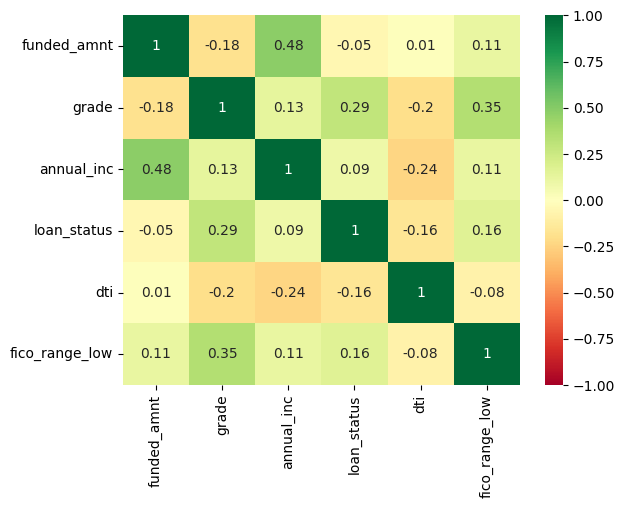

In [28]:
corr = dataset_predict.corr(numeric_only=True).round(2)
sns.heatmap(corr, cmap="RdYlGn", annot=True, vmin=-1, vmax=1)

### Now we divide all categorical attributes into dummies and divide two datasets into X and Y. Where X has only predicting attributes and Y has attribute to be predicted.

In [29]:
delete_columns = ['home_ownership_ANY', 'purpose_wedding','purpose_educational','purpose_other']

X = pd.get_dummies(dataset_predict).drop(['loan_status']+delete_columns,axis = 1)
Y = dataset_predict["loan_status"]

In [30]:
from sklearn.preprocessing import StandardScaler

X = pd.DataFrame(
    data = (StandardScaler()
            .fit_transform(X)),
    columns = X.columns)

### We use the train_test_split function from sklearn to divide our datasets into training and testing.

In [31]:
from sklearn.model_selection import train_test_split

x_train, x_test, y_train, y_test = train_test_split(X,Y, test_size = 0.3)

### We train a Random Forest classifier and evaluate it with stratified 5-fold cross-validation and a held-out test set.

In [32]:
from sklearn.metrics import accuracy_score
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import StratifiedKFold

i=1 
kf = StratifiedKFold(n_splits=5,random_state=1,shuffle=True) 

for train_index,test_index in kf.split(X,Y):
     xtr,xvl = X.iloc[train_index],X.iloc[test_index]
     ytr,yvl = Y.iloc[train_index],Y.iloc[test_index]
     model = RandomForestClassifier(random_state=1, max_depth=10)
     model.fit(xtr, ytr)
     predict_test = model.predict(xvl)
     score = accuracy_score(yvl,predict_test)
     print('n{} of kfold {} accuracy_score {}'.format(i,kf.n_splits,score))
     i+=1

predict_test = model.predict(x_test)

n1 of kfold 5 accuracy_score 0.7455260303687635
n2 of kfold 5 accuracy_score 0.74474647505423
n3 of kfold 5 accuracy_score 0.7473223969631236
n4 of kfold 5 accuracy_score 0.7466020404704606
n5 of kfold 5 accuracy_score 0.7481273090872115


In [33]:
predict_test = model.predict(x_test)

In [34]:
accuracy_score(y_test,predict_test) # 0.7561912509038322

0.7547451193058569

In [35]:
importances=pd.Series(model.feature_importances_, index=X.columns) 

In [36]:
importances.nlargest(5)

grade              0.363985
dti                0.151531
fico_range_low     0.114747
annual_inc         0.080508
term_ 60 months    0.075805
dtype: float64

<Axes: >

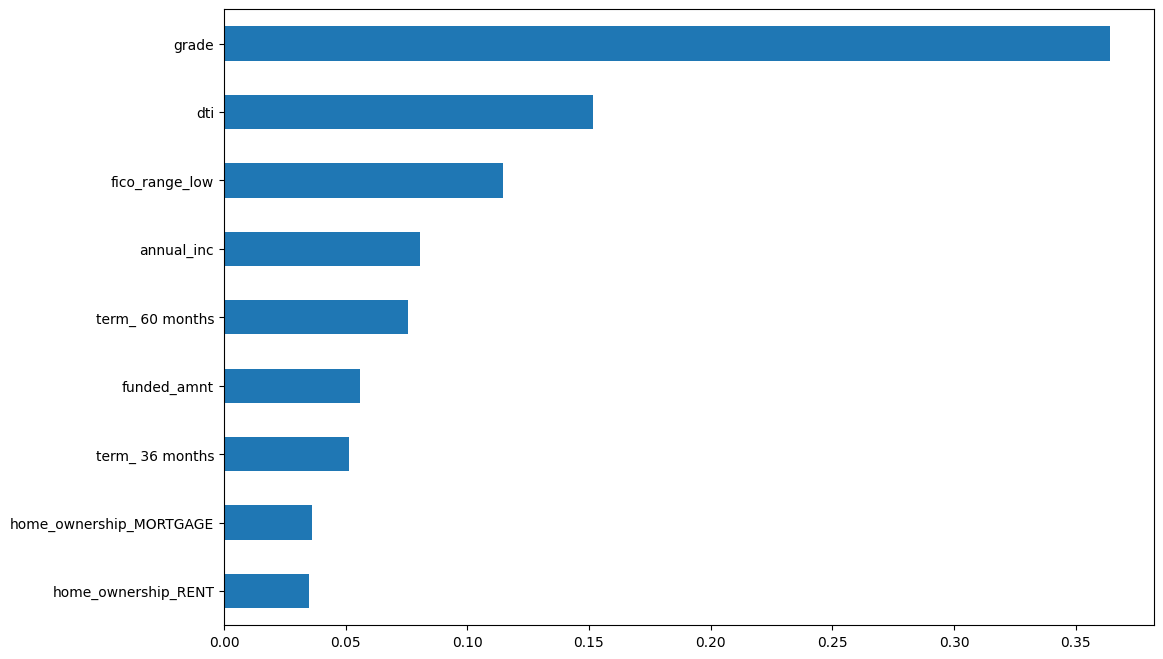

In [37]:
importances[importances > 0.025].sort_values().plot(kind='barh', figsize=(12,8))

In [38]:
dataset_current = dataset.copy()

In [39]:
dataset_current.drop(
    ['emp_length', 'delinq_2yrs',
     'zip_code','addr_state','emp_title'], 
    axis=1, 
    inplace=True)

In [40]:
delete_columns = ['home_ownership_ANY', 'purpose_wedding','purpose_educational','purpose_other']

X = pd.get_dummies(dataset_current.drop(['loan_status'], axis = 1)).drop(delete_columns,axis = 1)

In [41]:
from sklearn.preprocessing import StandardScaler

X = pd.DataFrame(
    data = (StandardScaler()
            .fit_transform(X)),
    columns = X.columns)

In [42]:
prediction = model.predict(X)

In [43]:
backup = dataset.copy()

In [44]:
dataset["predicted_loan_status"] = prediction

In [45]:
dataset

,funded_amnt,term,grade,emp_title,emp_length,home_ownership,annual_inc,loan_status,purpose,zip_code,addr_state,dti,delinq_2yrs,fico_range_low,predicted_loan_status
0,18000,36 months,7,Systems Support Engineer,5.0,MORTGAGE,75000.0,Current,debt_consolidation,030xx,New Hampshire,25.65,0,715,True
1,7200,36 months,4,Department Manager,9.0,OWN,20000.0,Late (31-120 days),debt_consolidation,023xx,Massachusetts,13.21,1,705,True
2,5000,36 months,6,Accounts Payable Manager,6.0,OWN,72000.0,Current,other,280xx,North Carolina,6.52,0,710,True
3,15000,60 months,5,Counselor,4.0,RENT,77213.0,Fully Paid,credit_card,347xx,Florida,18.17,0,670,True
4,3600,36 months,6,Systems Administrator,0.0,MORTGAGE,85000.0,Current,debt_consolidation,220xx,Virginia,17.44,0,675,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
421090,24000,36 months,6,Director of Maintenance,10.0,MORTGAGE,79000.0,Current,home_improvement,072xx,New Jersey,3.90,0,660,True
421091,10000,36 months,6,Office Assistant,8.0,RENT,31000.0,Current,debt_consolidation,905xx,California,28.69,0,670,True
421092,12000,60 months,3,Painter,1.0,RENT,64400.0,Charged Off,debt_consolidation,010xx,Massachusetts,27.19,1,695,False
421093,13000,60 months,4,Radiologist Technologist,5.0,RENT,35000.0,Charged Off,debt_consolidation,378xx,Tennessee,30.90,0,680,False


In [ ]:
predict_dict = {False : "Charged Off", True : "Fully Paid"}

In [ ]:
dataset["predicted_loan_status"] = dataset["predicted_loan_status"].map(predict_dict).astype("string")

In [ ]:
# OPTIONAL
grade_map = pd.Series(
    data = np.arange(7,0,-1), 
    index = (dataset["grade"]
             .value_counts()
             .sort_index()
             .index)
    ).to_dict()

In [ ]:
# OPTIONAL
dataset["grade"] = (
    dataset["grade"]
    .map(grade_map)
    .astype("uint8",
            errors = 'ignore'))

In [ ]:
dataset

,funded_amnt,term,grade,emp_title,emp_length,home_ownership,annual_inc,loan_status,purpose,zip_code,addr_state,dti,delinq_2yrs,fico_range_low,predicted_loan_status
0,18000,36 months,7,Systems Support Engineer,5.0,MORTGAGE,75000.0,Current,debt_consolidation,030xx,New Hampshire,25.65,0,715,Fully Paid
1,7200,36 months,4,Department Manager,9.0,OWN,20000.0,Late (31-120 days),debt_consolidation,023xx,Massachusetts,13.21,1,705,Fully Paid
2,5000,36 months,6,Accounts Payable Manager,6.0,OWN,72000.0,Current,other,280xx,North Carolina,6.52,0,710,Fully Paid
3,15000,60 months,5,Counselor,4.0,RENT,77213.0,Fully Paid,credit_card,347xx,Florida,18.17,0,670,Fully Paid
4,3600,36 months,6,Systems Administrator,0.0,MORTGAGE,85000.0,Current,debt_consolidation,220xx,Virginia,17.44,0,675,Fully Paid
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
421090,24000,36 months,6,Director of Maintenance,10.0,MORTGAGE,79000.0,Current,home_improvement,072xx,New Jersey,3.90,0,660,Fully Paid
421091,10000,36 months,6,Office Assistant,8.0,RENT,31000.0,Current,debt_consolidation,905xx,California,28.69,0,670,Fully Paid
421092,12000,60 months,3,Painter,1.0,RENT,64400.0,Charged Off,debt_consolidation,010xx,Massachusetts,27.19,1,695,Charged Off
421093,13000,60 months,4,Radiologist Technologist,5.0,RENT,35000.0,Charged Off,debt_consolidation,378xx,Tennessee,30.90,0,680,Charged Off


In [ ]:
dataset.loc[dataset.loan_status == 'Charged Off', 'predicted_loan_status'] = "Charged Off"
dataset.loc[dataset.loan_status == 'Fully Paid', 'predicted_loan_status'] = "Fully Paid"

In [ ]:
dataset.predicted_loan_status.value_counts()

predicted_loan_status
Fully Paid     366960
Charged Off     52131
Name: count, dtype: Int64

---

In [ ]:
dataset.to_excel("predicted_data_accepted_new.xlsx")

---